In [1]:
# import os

# # Use conda's newer libstdc++ instead of the system one
# conda_lib = os.path.expanduser("~/.conda/envs/hnn-core-env/lib")
# ld_path = os.environ.get("LD_LIBRARY_PATH", "")
# os.environ["LD_LIBRARY_PATH"] = f"{conda_lib}:{ld_path}"

# # UCX settings (from before)
# os.environ["UCX_TLS"] = "tcp,self,sm"
# os.environ["UCX_NET_DEVICES"] = "all"


# # MPI paths
# mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
# mpi_lib = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/lib"
# if mpi_bin not in os.environ["PATH"]:
#     os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"
# if mpi_lib not in ld_path:
#     os.environ["LD_LIBRARY_PATH"] = f"{mpi_lib}:{os.environ['LD_LIBRARY_PATH']}"

# import sys
# # Add MPI bin directory to PATH
# mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
# if mpi_bin not in os.environ["PATH"]:
#     os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"

# print("Updated PATH to include MPI")
# print("MPI location:", mpi_bin)

# import os
# print("PATH:", os.environ.get('PATH', 'NOT SET'))
# print("Which mpiexec:")
# import subprocess
# result = subprocess.run(['which', 'mpiexec'], capture_output=True, text=True)
# print(result.stdout if result.returncode == 0 else "mpiexec not found")

In [2]:
import os
import os.path as op
import numpy as np
import matplotlib.pyplot as plt

import hnn_core
from hnn_core.externals.mne import tfr_array_morlet
from hnn_core.viz import plot_tfr_morlet
from hnn_core import MPIBackend, JoblibBackend, average_dipoles

import sys
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/')
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils')
from general_plot_utils import assign_color

from hnn_core import duecker_ET_model, simulate_dipole
import matplotlib.pyplot as plt
import numpy as np
from hnn_core.externals.mne import tfr_array_morlet
pathfig = '//Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/gamma'
os.makedirs(pathfig, exist_ok=True)

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
n_procs=10

In [3]:
def plot_single_trial_sim(net, dpl):

    fig = plt.figure(figsize=(20,8))

    gs = fig.add_gridspec(5,8, height_ratios=[.25, 0.25, 0.25, 0.25, 1.25], width_ratios=[0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5], hspace=0.5, wspace=0.6)
    axempty = fig.add_subplot(gs[1:4,:2])
    axempty.set_axis_off()
    ax00 = fig.add_subplot(gs[0,2:5])
    ax10 = fig.add_subplot(gs[1:4,2:5])
    ax11 = fig.add_subplot(gs[0:2,5:])
    ax21 = fig.add_subplot(gs[2:4,5:])
    ax3 = fig.add_subplot(gs[4,:2])
    ax4 = fig.add_subplot(gs[4,2:4])
    ax5 = fig.add_subplot(gs[4, 4])
    ax6 = fig.add_subplot(gs[4, 5])
    ax7 = fig.add_subplot(gs[4, 6])
    ax8 = fig.add_subplot(gs[4, 7])
    # ax9 = fig.add_subplot(gs[4, 4:6])
    # axreal10 = fig.add_subplot(gs[4, 6:])

    # drives
    bins = np.arange(0, 1000, 5)
    spike_prox1 = np.array(net.cell_response.spike_times_by_type['prox_poiss'][0]).reshape(-1,1)

    ax00.hist(spike_prox1, bins=bins, color='r')
    ax00.set_xlim([0, 1000])
    ax00.set_xticks(np.arange(0, 1001, 250))

    ax00.set_xticklabels([])            
    # dipole
    ax10.plot(dpl[0].times, dpl[0].data['agg'], color='k', linewidth=1)
    ax10.set_ylabel('diple (nA·m)')
    ax10.set_xlim([0, 1000])
    ax10.spines['top'].set_visible(False)
    ax10.spines['right'].set_visible(False)
    ax10.set_xlabel('time (ms)')
    ax10.set_xticks(np.arange(0, 1001, 250))


    # dipole and raster
    I = np.array(net.cell_response.spike_gids[0]) < 135
    gids = np.array(net.cell_response.spike_gids[0]).reshape(-1,)[I]
    times = np.array(net.cell_response.spike_times[0]).reshape(-1,)[I] 
    colors = [assign_color(net, gid) for gid in gids]

    ax11.plot(dpl[0].times, dpl[0].data['L2'], color='k', alpha=0.25)
    ax11.set_ylim([0, 0.01])
    ax11.set_xlim([0, 1000])
    ax11.set_xticks(np.arange(0, 1001, 250))

    ax11.set_ylabel('dipole (nA·m)')
    ax11.set_yticks([0.0, 0.005, 0.01])
    ax12 = ax11.twinx()

    ax12.scatter(times, gids, s=15, alpha=1., c=colors, marker='|')
    ax12.set_ylabel('L2/3 neurons')
    ax12.set_xticklabels([])
    ax12.invert_yaxis()
    ax12.set_yticks([0, 35, 135])
    ax12.set_xticks(np.arange(0, 1001, 250))


    I = (np.array(net.cell_response.spike_gids[0]) >= 135) & (np.array(net.cell_response.spike_gids[0]) < 270)
    gids = np.array(net.cell_response.spike_gids[0]).reshape(-1,)[I]
    times = np.array(net.cell_response.spike_times[0]).reshape(-1,)[I] 
    colors = [assign_color(net, gid) for gid in gids]

    ax21.plot(dpl[0].times, dpl[0].data['L5'], color='k', alpha=0.25)
    ax21.set_xlim([0, 1000])
    ax21.set_ylim([-0.015, 0.03])
    ax21.set_yticks([-0.015, 0.0, 0.015, 0.03])
    ax21.set_xticks(np.arange(0, 1001, 250))

    ax22 = ax21.twinx()
    ax22.scatter(times, gids, s=15, alpha=1., c=colors, marker='|')
    ax22.set_ylabel('L5 neurons')
    ax22.invert_yaxis()
    ax22.set_yticks([135, 170, 270])
    ax22.set_xlabel('time (ms)')
    ax22.set_xticks(np.arange(0, 1001, 250))

    # TFR
    freqs = np.arange(20, 81, 1)

    tfr = np.zeros((len(dpl), len(freqs), len(dpl[0].times)))

    for i,d in enumerate(dpl):

        cur_tfr = tfr_array_morlet(d.data["agg"][None, None, :], d.sfreq, freqs, output='power')
        tfr[i] = cur_tfr.squeeze()

    tfr = tfr.mean(axis=0)
    
    im = ax3.pcolormesh(dpl[0].times, freqs, tfr, shading='auto', cmap='Reds', vmin=0, vmax=np.round(tfr.max()+0.05,1), rasterized=True)
    cb = plt.colorbar(im, pad=0.025)
    cb.set_ticks([0, np.round(tfr.max()+0.05,1)])
    cb.set_label('power (nA·m)^2')
    ax3.set_xlabel('time (ms)')
    ax3.set_yticks([20, 40, 60, 80])
    ax3.set_ylabel('frequency (Hz)')

    # PSD
    from scipy.signal import periodogram
    freqs, Pxx = periodogram(dpl[0].data['agg'], dpl[0].sfreq, window="hamming", nfft=len(dpl[0].data['agg']))
    ax4.plot(freqs, Pxx, color='k', linewidth=2)
    ax4.set_xlim([20, 80])
    ax4.text(freqs[np.argmax(Pxx)], np.max(Pxx), f'{np.round(freqs[np.argmax(Pxx)]):.0f}Hz')
    ax4.spines['top'].set_visible(False)
    ax4.spines['right'].set_visible(False)
    ax4.set_xlabel('frequency (Hz)')
    ax4.set_xticks([20,40,60,80])


    # calcium

    l23_cols_tone = ['#110308', '#420d20', '#741638', '#a52050']

    U, C = np.unique(np.array(net.cell_response.spike_gids[0])[(np.array(net.cell_response.spike_gids[0]) < 135) & (np.array(net.cell_response.spike_gids[0]) >= 35)], return_counts=True)
    gid_oi = U[np.argmax(C)]

    sections = ['soma', 'apical_trunk', 'apical_1', 'apical_tuft']

    L = []
    for section in sections:
        L.append(net.cell_types["L2_pyramidal"]['cell_object'].sections[section].L)
    prevL = 0
    for i, section in enumerate(sections):

        v = np.array(net.cell_response.vsec[0][gid_oi][section])
        ca = np.array(net.cell_response.ca[0][gid_oi][section])
        ax5.plot(net.cell_response.times, v + i*120, color=l23_cols_tone[i], linewidth=1.5)
        ax6.plot(net.cell_response.times, ca + i *1e-4, color=l23_cols_tone[i], linewidth=1.5)
        prevL += L[i]
    ax5.spines['left'].set_bounds([-70, 30])
    ax5.spines['bottom'].set_bounds([0, 50])
    ax5.set_xticks([])
    ax5.set_yticks([])
    ax5.spines['top'].set_visible(False)
    ax5.spines['right'].set_visible(False)

    ax6.spines['left'].set_bounds([5e-5, 7.5e-5])
    ax6.spines['bottom'].set_bounds([0, 50])
    ax6.set_xticks([])
    ax6.set_yticks([])
    ax6.spines['top'].set_visible(False)
    ax6.spines['right'].set_visible(False)

    U, C = np.unique(np.array(net.cell_response.spike_gids[0])[(np.array(net.cell_response.spike_gids[0]) < 270) & (np.array(net.cell_response.spike_gids[0]) >= 170)], return_counts=True)
    gid_oi = U[np.argmax(C)]

    sections = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
    l5_cols_tone = ['k','#2A3760','#36477B','#425796', '#5C72B7']

    L = []
    for section in sections:
        L.append(net.cell_types["L5ET"]['cell_object'].sections[section].L)
    prevL = 0
    for i, section in enumerate(sections):

        v = np.array(net.cell_response.vsec[0][gid_oi][section])
        ca = np.array(net.cell_response.ca[0][gid_oi][section])
        ax7.plot(net.cell_response.times, v + i*120, color=l5_cols_tone[i], linewidth=1.5)
        ax8.plot(net.cell_response.times, ca + i *1e-4, color=l5_cols_tone[i], linewidth=1.5)
        prevL += L[i]
    ax7.spines['left'].set_bounds([-70, 30])
    ax7.spines['bottom'].set_bounds([0, 50])
    ax7.set_xticks([])
    ax7.set_yticks([])
    ax7.spines['top'].set_visible(False)
    ax7.spines['right'].set_visible(False)

    ax8.spines['left'].set_bounds([5e-5, 7.5e-5])
    ax8.spines['bottom'].set_bounds([0, 50])
    ax8.set_xticks([])
    ax8.set_yticks([])
    ax8.spines['top'].set_visible(False)
    ax8.spines['right'].set_visible(False)


    l23_tuft_ca = np.zeros((100, len(dpl[0].times)))

    # sort gids based on distance

    l23idx = np.argsort(np.sum(np.abs(np.array(net.pos_dict["L2_pyramidal"]) - np.array([4,4,1.3074e+03])), axis=1))
    idx=0
    for i in l23idx:
        gid = net.gid_ranges["L2_pyramidal"][i]
        l23_tuft_ca[idx] = net.cell_response.ca[0][gid]['apical_tuft']
        idx+=1
        
    # # convert to micro molar
    # l23_tuft_ca *=1e3
    # im = ax9.pcolormesh(net.cell_response.times, np.arange(100), l23_tuft_ca, shading='auto', cmap='RdPu', rasterized=True)
    # cb1 = plt.colorbar(im, ax=ax9)
    # cb1.set_ticks([5e-2, l23_tuft_ca.max()])
    # cb1.set_ticklabels([f'{5e-2:.3}', f'{l23_tuft_ca.max():.3}'])
    # ax9.set_ylim([0, 100])
    # ax9.set_yticks([0, 50, 100])
    # ax9.set_xticks(np.arange(0, 1001, 250))
    # ax9.set_xlabel('time (ms)')

    # # L5 calcium
    # l5_tuft_ca = np.zeros((100, len(dpl[0].times)))

    # l5idx = np.argsort(np.sum(np.abs(np.array(net.pos_dict["L5ET"]) - np.array([4,4,1.3074e+03])), axis=1))
    # idx=0
    # for i in l5idx:
    #     gid = net.gid_ranges["L5ET"][i]
    #     l5_tuft_ca[idx] = net.cell_response.ca[0][gid]['apical_tuft']
    #     idx+=1

    # # convert to micromolar
    # l5_tuft_ca *=1e3
    # im = axreal10.pcolormesh(net.cell_response.times, np.arange(100), l5_tuft_ca, shading='auto', cmap='BuPu', rasterized=True, vmax=l5_tuft_ca.max())
    # cb3 = plt.colorbar(im, ax=axreal10)
    # cb3.set_ticks([l5_tuft_ca.min(), l5_tuft_ca.max()])
    # cb3.set_ticklabels([f'{5e-2:.3}', f'{l5_tuft_ca.max():.3}'])
    # axreal10.set_ylim([0, 100])
    # axreal10.set_yticks([0, 50, 100])
    # axreal10.set_xticks(np.arange(0, 1001, 250))
    # axreal10.set_xlabel('time (ms)')

    return fig




def plot_multi_trial_sim(net, dpl):

    fig = plt.figure(constrained_layout=True, figsize=(20,3.5))

    gs = fig.add_gridspec(4,4, height_ratios=[.25, 0.25, 0.25, 0.25], hspace=0.3, wspace=.4)
    ax00 = fig.add_subplot(gs[0,0])
    ax10 = fig.add_subplot(gs[1:4,0])
    ax11 = fig.add_subplot(gs[0:2,1])
    ax21 = fig.add_subplot(gs[2:,1])
    ax3 = fig.add_subplot(gs[:,2])
    ax4 = fig.add_subplot(gs[:,3])

    # drives
    bins = np.arange(0, 1000, 5)
    spike_prox1 = np.array(net.cell_response.spike_times_by_type['prox_poiss'][0]).reshape(-1,1)

    ax00.hist(spike_prox1, bins=bins, color='r')
    ax00.set_xlim([0, 1000])
    ax00.set_xticklabels([])  
    ax00.set_xticks(np.arange(0, 1001, 250))
          
    # dipole
    ax10.plot(dpl[0].times, dpl[0].data['agg'], color='k', linewidth=1)
    ax10.set_ylabel('diple (nA·m)')
    ax10.set_xlim([0, 1000])
    ax10.set_xticks(np.arange(0, 1001, 250))
    ax10.spines['top'].set_visible(False)
    ax10.spines['right'].set_visible(False)
    ax10.set_xlabel('time (ms)')

    # dipole and raster
    I = np.array(net.cell_response.spike_gids[0]) < 135
    gids = np.array(net.cell_response.spike_gids[0]).reshape(-1,)[I]
    times = np.array(net.cell_response.spike_times[0]).reshape(-1,)[I] 
    colors = [assign_color(net, gid) for gid in gids]

    ax11.plot(dpl[0].times, dpl[0].data['L2'], color='k', alpha=0.25)
    ax11.set_ylim([0, 0.01])
    ax11.set_xlim([0, 1000])
    ax11.set_xticks(np.arange(0, 1001, 250))
    
    ax11.set_ylabel('dipole (nA·m)')
    ax11.set_yticks([0.0, 0.005, 0.01])
    ax12 = ax11.twinx()

    ax12.scatter(times, gids, s=15, alpha=1., c=colors, marker='|')
    ax12.set_ylabel('L2/3 neurons')
    ax12.set_xticklabels([])
    ax12.invert_yaxis()
    ax12.set_yticks([0, 35, 135])
    ax12.set_xticks(np.arange(0, 1001, 250))


    I = (np.array(net.cell_response.spike_gids[0]) >= 135) & (np.array(net.cell_response.spike_gids[0]) < 270)
    gids = np.array(net.cell_response.spike_gids[0]).reshape(-1,)[I]
    times = np.array(net.cell_response.spike_times[0]).reshape(-1,)[I] 
    colors = [assign_color(net, gid) for gid in gids]

    ax21.plot(dpl[0].times, dpl[0].data['L5'], color='k', alpha=0.25)
    ax21.set_xlim([0, 1000])
    ax21.set_xticks(np.arange(0, 1001, 250))

    ax21.set_ylim([-0.015, 0.03])
    ax21.set_yticks([-0.015, 0.0, 0.015, 0.03])
    ax22 = ax21.twinx()
    ax22.scatter(times, gids, s=15, alpha=1., c=colors, marker='|')
    ax22.set_ylabel('L5 neurons')
    ax22.invert_yaxis()
    ax22.set_yticks([135, 170, 270])
    ax21.set_xlabel('time (ms)')
    ax22.set_xticks(np.arange(0, 1001, 250))

    # TFR
    freqs = np.arange(20, 81, 1)

    cur_tfr = tfr_array_morlet(dpl[0].data["agg"][None, None, :], dpl[0].sfreq, freqs, output='power')
    tfr = cur_tfr.squeeze()
    
    im = ax3.pcolormesh(dpl[0].times, freqs, tfr, shading='auto', cmap='RdBu_r', vmin=0, vmax=np.round(tfr.max()+0.01,1), rasterized=True)
    cb = plt.colorbar(im, pad=0.025)
    cb.set_ticks([0, np.round(tfr.max()+0.05,1)])
    cb.set_label('power (nA·m)^2')
    ax3.set_xlabel('time (ms)')
    ax3.set_yticks([20, 40, 60, 80])
    ax3.set_ylabel('frequency (Hz)')
    ax3.set_xticks(np.arange(0, 1001, 250))


    # average over trials

    tfr = np.zeros((len(dpl), len(freqs), len(dpl[0].times)))

    for i,d in enumerate(dpl):

        cur_tfr = tfr_array_morlet(d.data["agg"][None, None, :], d.sfreq, freqs, output='power')
        tfr[i] = cur_tfr.squeeze()

    tfr = tfr.mean(axis=0)
    
    im = ax4.pcolormesh(dpl[0].times, freqs, tfr, shading='auto', cmap='RdBu_r', vmin=0, vmax=np.round(tfr.max()+0.01,1), rasterized=True)
    cb = plt.colorbar(im, pad=0.025)
    cb.set_ticks([0, np.round(tfr.max(),1)])
    cb.set_label('power (nA·m)^2')
    ax4.set_xlabel('time (ms)')
    ax4.set_yticks([20, 40, 60, 80])
    ax4.set_ylabel('frequency (Hz)')
    ax4.set_xticks(np.arange(0, 1001, 250))


    return fig

In [4]:
hnn_core_root = op.dirname(hnn_core.__file__)
params_fname = op.join(hnn_core_root, 'param', 'gamma_human_ET50Hz_sustained.json')
params = hnn_core.read_params(params_fname)

net = duecker_ET_model(params)

weights_ampa = {'L2_pyramidal': 0.0045, 'L5ET': 0.0055}
weights_nmda = {'L2_pyramidal': 0.0045, 'L5ET': 0.0055}
synaptic_delays = {'L2_pyramidal': 0.1, 'L5ET': 1.0}
rate_constant = {'L2_pyramidal': 200.0, 'L5ET': 200.0}

net.add_poisson_drive('prox_poiss', tstart=0, tstop=1000, rate_constant=rate_constant, weights_ampa=weights_ampa, weights_nmda=weights_nmda,
    location='proximal', synaptic_delays=synaptic_delays,
    event_seed=1349)

#with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
dpl = simulate_dipole(net, tstop=1000,bsl_cor='duecker', n_trials=1, record_ca='all', record_vsec='all')



Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Trial 1: 180.0 ms...
Trial 1: 190.0 ms...
Trial 1: 200.0 ms...
Trial 1: 210.0 ms...
Trial 1: 220.0 ms...
Trial 1: 230.0 ms...
Trial 1: 240.0 ms...
Trial 1: 250.0 ms...
Trial 1: 260.0 ms...
Trial 1: 270.0 ms...
Trial 1: 280.0 ms...
Trial 1: 290.0 ms...
Trial 1: 300.0 ms...
Trial 1: 310.0 ms...
Trial 1: 320.0 ms...
Trial 1: 330.0 ms...
Trial 1: 340.0 ms...
Trial 1: 350.0 ms...
Tr

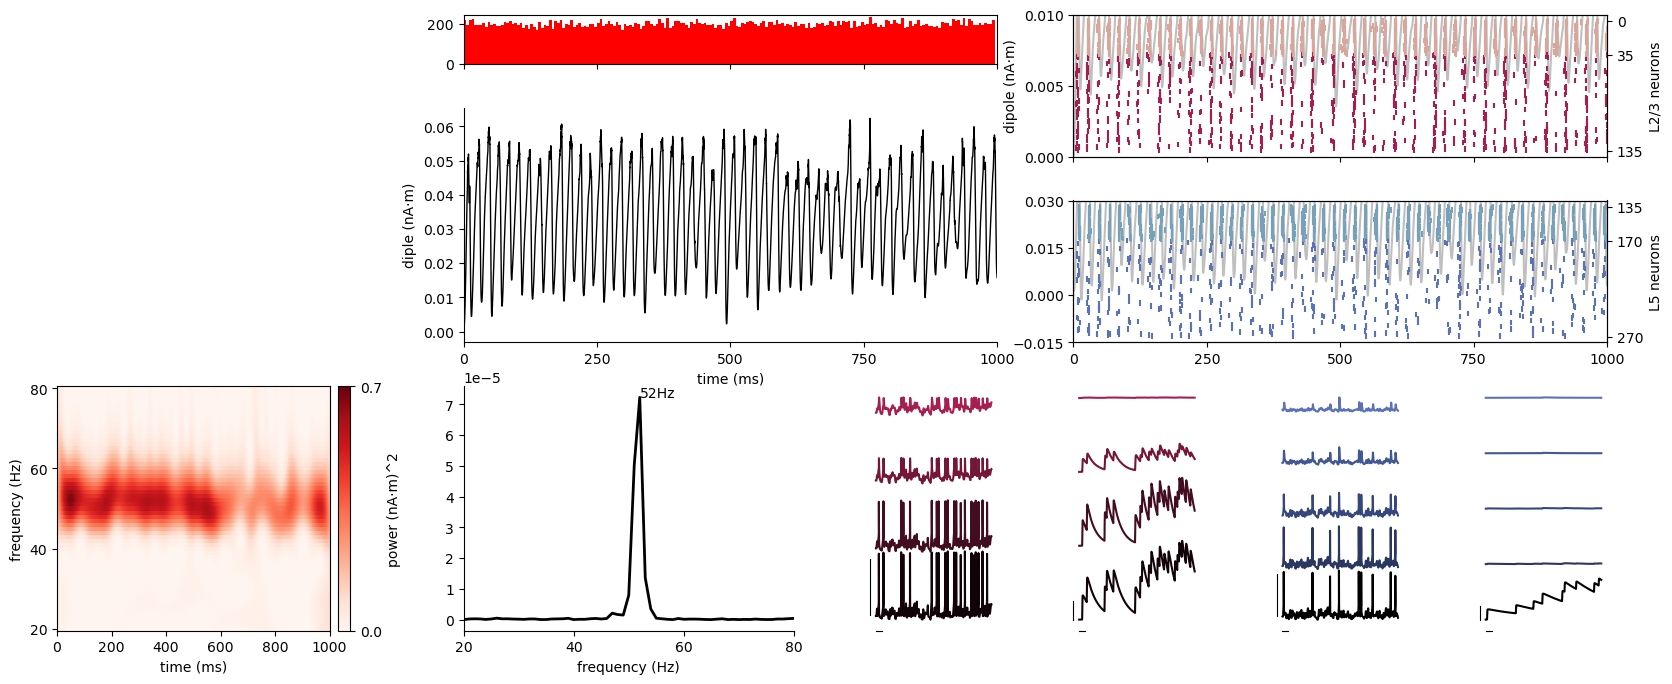

: 

In [ ]:
fig = plot_single_trial_sim(net, dpl)

fig.savefig(op.join(pathfig, 'gamma_ET_model_sustained.png'))
fig.savefig(op.join(pathfig, 'gamma_ET_model_sustained.pdf'))

In [4]:
# bursty: reduce inhibition and reduce frequency and NMDA of drive
hnn_core_root = op.dirname(hnn_core.__file__)
params_fname = op.join(hnn_core_root, 'param', 'gamma_human_ET50Hz_bursty.json')
params = hnn_core.read_params(params_fname)

net = duecker_ET_model(params)
weights_ampa = {'L2_pyramidal': 0.0035, 'L5ET': 0.0055}
weights_nmda = {'L2_pyramidal': 0.0025, 'L5ET': 0.0035}
synaptic_delays = {'L2_pyramidal': 0.1, 'L5ET': 1.0}
rate_constant = {'L2_pyramidal': 100.0, 'L5ET': 100.0}
net.add_poisson_drive('prox_poiss', tstart=0, tstop=1000, rate_constant=rate_constant, weights_ampa=weights_ampa, weights_nmda=weights_nmda,
    location='proximal', synaptic_delays=synaptic_delays,
    event_seed=1349)

#with JoblibBackend(n_jobs=n_procs):
dpl = simulate_dipole(net, tstop=1000,bsl_cor='duecker', n_trials=40, record_ca='all', record_vsec='all')




Joblib will run 40 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Trial 1: 180.0 ms...
Trial 1: 190.0 ms...
Trial 1: 200.0 ms...
Trial 1: 210.0 ms...
Trial 1: 220.0 ms...
Trial 1: 230.0 ms...
Trial 1: 240.0 ms...
Trial 1: 250.0 ms...
Trial 1: 260.0 ms...
Trial 1: 270.0 ms...
Trial 1: 280.0 ms...
Trial 1: 290.0 ms...
Trial 1: 300.0 ms...
Trial 1: 310.0 ms...
Trial 1: 320.0 ms...
Trial 1: 330.0 ms...
Trial 1: 340.0 ms...
Trial 1: 350.0 ms...
T

: 

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_7098/1904508338.py:3: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(op.join(pathfig, 'gamma_ET_model_bursty.png'))
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_7098/1904508338.py:4: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(op.join(pathfig, 'gamma_ET_model_bursty.pdf'))
/Users/katharinaduecker/miniconda3/envs/hnn-core-env/lib/python3.12/site-packages/IPython/core/events.py:82: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/Users/katharinaduecker/miniconda3/envs/hnn-core-env/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes s

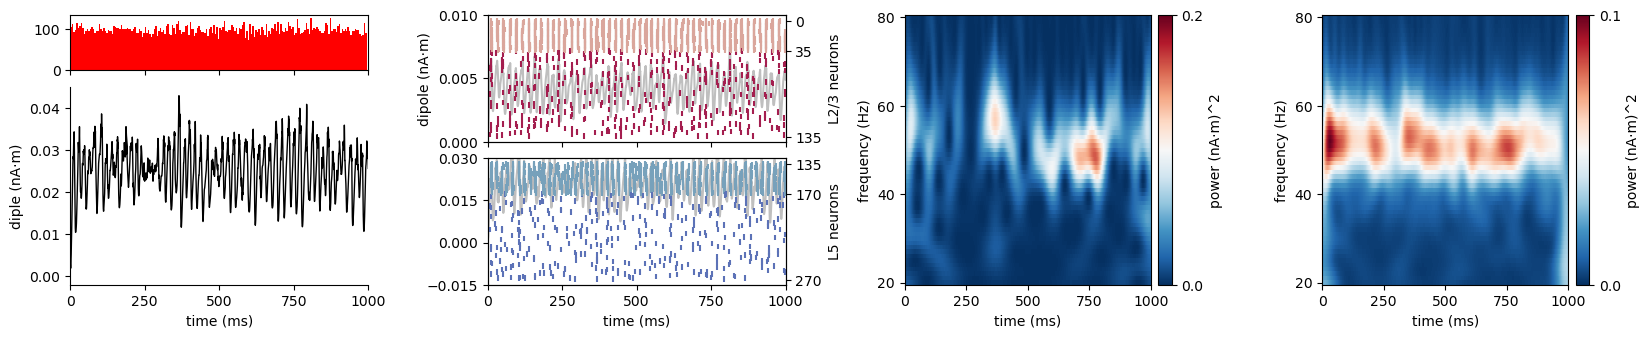

In [ ]:
fig = plot_multi_trial_sim(net, dpl)

fig.savefig(op.join(pathfig, 'gamma_ET_model_bursty.png'))
fig.savefig(op.join(pathfig, 'gamma_ET_model_bursty.pdf'))

import pickle
with open(op.join(pathfig, 'net_gamma_bursty.pkl'), 'wb') as f:
    pickle.dump(net, f)

with open(op.join(pathfig, "dpl_gamma_bursty.pkl"), 'wb') as f:
    pickle.dump(net,f)

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Trial 1: 180.0 ms...
Trial 1: 190.0 ms...
Trial 1: 200.0 ms...
Trial 1: 210.0 ms...
Trial 1: 220.0 ms...
Trial 1: 230.0 ms...
Trial 1: 240.0 ms...
Trial 1: 250.0 ms...
Trial 1: 260.0 ms...
Trial 1: 270.0 ms...
Trial 1: 280.0 ms...
Trial 1: 290.0 ms...
Trial 1: 300.0 ms...
Trial 1: 310.0 ms...
Trial 1: 320.0 ms...
Trial 1: 330.0 ms...
Trial 1: 340.0 ms...
Trial 1: 350.0 ms...
Tr

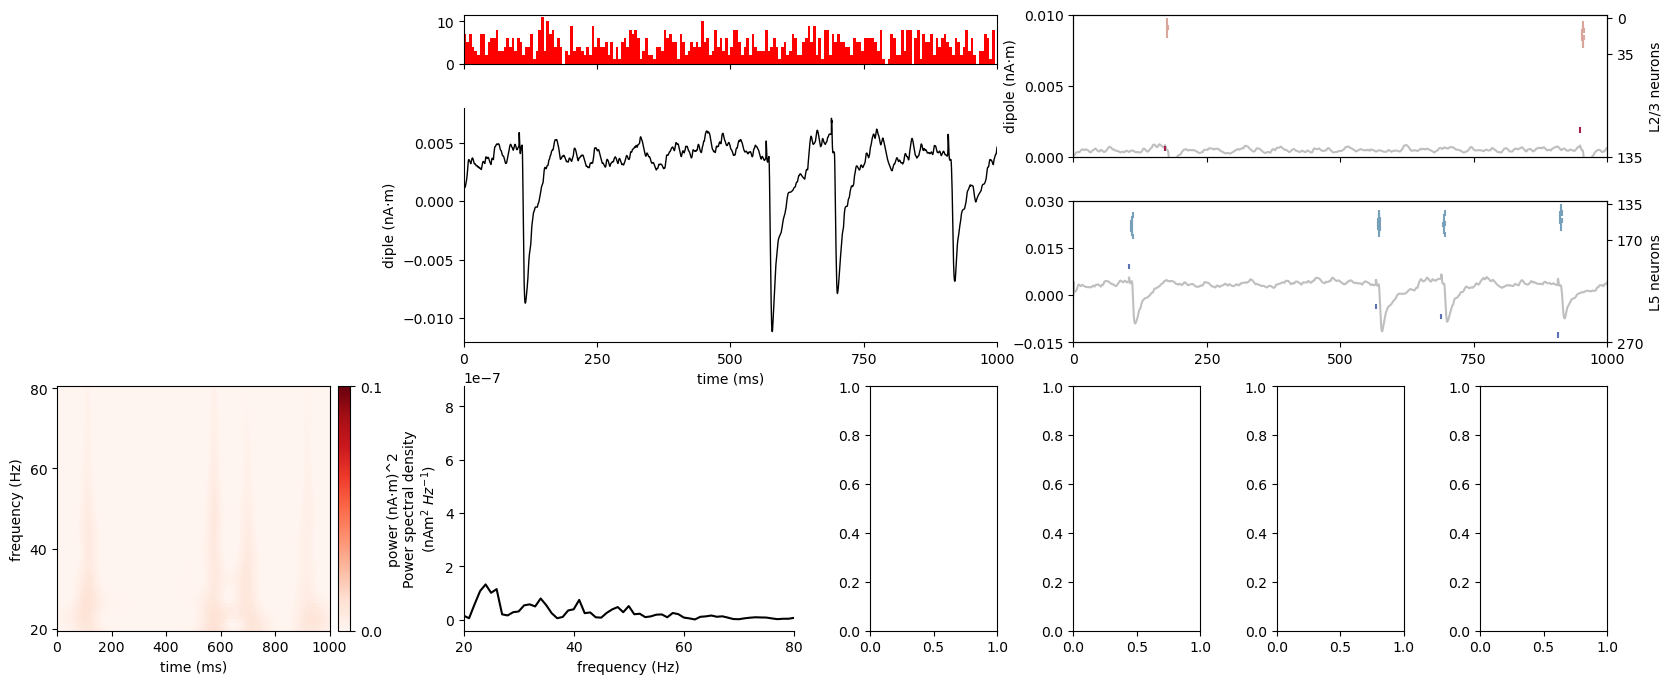

In [59]:
# sustained gamma 50 Hz - Neymotin reproduce?
hnn_core_root = op.dirname(hnn_core.__file__)
params_fname = op.join(hnn_core_root, 'param', 'gamma_human_ET50Hz_sustained.json')
params = hnn_core.read_params(params_fname)

net = duecker_ET_model(params)
weights_ampa = {'L2_pyramidal': 0.0035, 'L5ET': 0.0065}
weights_nmda = {'L2_pyramidal': 0.0012, 'L5ET': 0.0032}
synaptic_delays = {'L2_pyramidal': 0.1, 'L5ET': 1.0}
rate_constant = {'L2_pyramidal': 4.0, 'L5ET': 5.0}
net.add_poisson_drive('prox_poiss', tstart=0, tstop=1000, rate_constant=rate_constant, weights_ampa=weights_ampa, weights_nmda=weights_nmda,
    location='proximal', synaptic_delays=synaptic_delays,
    event_seed=1349)

#with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
dpl = simulate_dipole(net, tstop=1000,bsl_cor='duecker', n_trials=1, record_ca='all', record_vsec='all')


fig = plot_single_trial_sim(net, dpl)

fig.savefig(op.join(pathfig, 'gamma_ET_model_bursty_neymotin.png'))
fig.savefig(op.join(pathfig, 'gamma_ET_model_bursty_neymotin.pdf'))

In [ ]:
# Exploratory: duecker ET model in response to strong proximal followed by weak poissoin

hnn_core_root = op.dirname(hnn_core.__file__)

net = duecker_ET_model()
weights_ampa = {'L2_basket': 0.0, 'L2_pyramidal': 0.0035, 'L5_basket': 0.0, 'L5ET': 0.0035}
synaptic_delays = {'L2_basket':0.1, 'L2_pyramidal': 0.1, 'L5_basket': .1, 'L5ET': .1}
rate_constant = {'L2_basket': 200, 'L2_pyramidal': 200.0, 'L5_basket': 200, 'L5ET': 200.0}

net.add_poisson_drive('prox_poiss', tstart=0, tstop=1000, rate_constant=rate_constant, weights_ampa=weights_ampa,
    location='proximal', synaptic_delays=synaptic_delays,
    event_seed=1349)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=1000,bsl_cor='duecker', n_trials=1)

fig = plot_single_trial_sim(net, dpl)
